# Label-Free Handwritten Character-Region Proposals
This notebook uses Kraken's pretrained line segmentation, removes horizontal notebook rules, and proposes character crops with connected components and a conservative watershed split attempt.

**Important:** these are candidate regions, not guaranteed single-character crops. Inspect the preview before sending crops to your existing classifier.

## 1. Install dependencies
Run once in your `handwriting-seg` environment if needed. Restart the kernel after installing.

In [ ]:
%pip install kraken opencv-python pillow numpy

## 2. Configure input and output paths
Update `IMAGE_PATH` to your paragraph image. The default below matches your current test image.

In [1]:
from pathlib import Path
IMAGE_PATH = Path(r"C:\Users\Madhu\Desktop\DYSLEXIA\t3.png")
OUTPUT_DIR = Path(r"C:\Users\Madhu\Desktop\DYSLEXIA\segmentation_output_v2")
MIN_AREA = 18
MIN_HEIGHT = 7
PADDING = 3
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CROPS_DIR = OUTPUT_DIR / "crops"
CROPS_DIR.mkdir(parents=True, exist_ok=True)
print("Input exists:", IMAGE_PATH.exists())
print("Output directory:", OUTPUT_DIR)

Input exists: True
Output directory: C:\Users\Madhu\Desktop\DYSLEXIA\segmentation_output_v2


## 3. Imports and helper functions

In [2]:
import csv
import cv2
import numpy as np

import csv

import cv2
import numpy as np
from PIL import Image
from kraken import binarization, pageseg


def remove_horizontal_rules(ink):
    """Remove long horizontal notebook rules from a white-ink/black-background mask."""
    h, w = ink.shape
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (max(35, w // 18), 1))
    rules = cv2.morphologyEx(ink, cv2.MORPH_OPEN, kernel)
    rules = cv2.dilate(rules, cv2.getStructuringElement(cv2.MORPH_RECT, (3, 1)))
    return cv2.subtract(ink, rules), rules


def split_wide_component(component):
    """Conservative watershed split attempt for a connected, unusually wide component."""
    if cv2.countNonZero(component) < 30:
        return [component]
    dist = cv2.distanceTransform(component, cv2.DIST_L2, 5)
    peak = float(dist.max())
    if peak < 2.5:
        return [component]
    _, sure_fg = cv2.threshold(dist, max(2.0, 0.42 * peak), 255, 0)
    sure_fg = np.uint8(sure_fg)
    count, markers = cv2.connectedComponents(sure_fg)
    if count < 3:
        return [component]
    canvas = cv2.cvtColor(component, cv2.COLOR_GRAY2BGR)
    markers = markers.astype(np.int32)
    markers[component == 0] = 1
    markers[markers > 1] += 1
    cv2.watershed(canvas, markers)
    pieces = []
    for label in np.unique(markers):
        if label <= 1:
            continue
        piece = np.uint8(markers == label) * 255
        if cv2.countNonZero(piece) >= 12:
            pieces.append(piece)
    return pieces if len(pieces) >= 2 else [component]


def candidate_boxes(mask, min_area, min_height, page_width):
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    boxes = []
    for i in range(1, n):
        x, y, w, h, area = map(int, stats[i])
        if area < min_area or h < min_height:
            continue
        if w > max(2.5 * h, 0.18 * page_width) and area > 2 * min_area:
            local = np.uint8(labels[y:y+h, x:x+w] == i) * 255
            pieces = split_wide_component(local)
            if len(pieces) > 1:
                for piece in pieces:
                    px, py, pw, ph = cv2.boundingRect(piece)
                    if pw > 0 and ph >= min_height and cv2.countNonZero(piece) >= min_area:
                        boxes.append((x+px, y+py, x+px+pw, y+py+ph))
                continue
        boxes.append((x, y, x+w, y+h))
    return boxes




## 4. Run Kraken line segmentation and remove notebook rules
This cell creates debug images so you can check whether horizontal rules were removed.

In [3]:
import cv2
import numpy as np
from PIL import Image
from kraken import binarization, pageseg

if not IMAGE_PATH.exists():
    raise FileNotFoundError(f"Input image not found: {IMAGE_PATH}")

pil = Image.open(IMAGE_PATH).convert("RGB")
original = cv2.cvtColor(np.array(pil), cv2.COLOR_RGB2BGR)
H, W = original.shape[:2]
kraken_bw = binarization.nlbin(pil)
seg = pageseg.segment(kraken_bw)

line_preview = original.copy()
line_boxes = []
for line in seg.lines:
    x1, y1, x2, y2 = map(int, line.bbox)
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    if x2 > x1 and y2 > y1:
        line_boxes.append((x1, y1, x2, y2))
        cv2.rectangle(line_preview, (x1, y1), (x2, y2), (0, 255, 0), 2)
cv2.imwrite(str(OUTPUT_DIR / "01_line_preview.jpg"), line_preview)

bw = np.array(kraken_bw.convert("L"))
if np.mean(bw) > 127:
    ink = cv2.threshold(bw, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
else:
    ink = cv2.threshold(bw, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
cleaned, rules = remove_horizontal_rules(ink)
cv2.imwrite(str(OUTPUT_DIR / "debug_ink_before.png"), ink)
cv2.imwrite(str(OUTPUT_DIR / "debug_removed_rules.png"), rules)
cv2.imwrite(str(OUTPUT_DIR / "debug_ink_after.png"), cleaned)

print("Detected Kraken lines:", len(seg.lines))
print("Image size:", W, "x", H)


Detected Kraken lines: 17
Image size: 907 x 787


## 5. Generate candidate character boxes

In [4]:
heights = [y2-y1 for _, y1, _, y2 in line_boxes if y2-y1 > 5]
typical_line_height = float(np.median(heights)) if heights else 45.0
effective_min_height = max(MIN_HEIGHT, int(typical_line_height * 0.12))
boxes = candidate_boxes(cleaned, MIN_AREA, effective_min_height, W)

filtered = []
for x1, y1, x2, y2 in boxes:
    w, h = x2-x1, y2-y1
    if w > 0.45 * W and h < 0.20 * typical_line_height:
        continue
    filtered.append((x1, y1, x2, y2))
boxes = sorted(filtered, key=lambda b: (b[1], b[0]))
print("Candidate boxes:", len(boxes))


Candidate boxes: 336


## 6. Save character crops, CSV coordinates, and preview

In [5]:
preview = original.copy()
csv_path = OUTPUT_DIR / "components.csv"
saved = 0
with csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["crop_file", "x1", "y1", "x2", "y2", "width", "height", "flag"])
    for x1, y1, x2, y2 in boxes:
        x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
        if x2 <= x1 or y2 <= y1:
            continue
        cx1, cy1 = max(0, x1-PADDING), max(0, y1-PADDING)
        cx2, cy2 = min(W, x2+PADDING), min(H, y2+PADDING)
        crop = original[cy1:cy2, cx1:cx2]
        if crop.size == 0:
            continue
        saved += 1
        name = f"char_{saved:04d}.png"
        cv2.imwrite(str(CROPS_DIR / name), crop)
        w, h = x2-x1, y2-y1
        flag = "review" if (w > 1.25*h or h > 1.6*typical_line_height) else ""
        color = (0, 165, 255) if flag else (0, 255, 0)
        cv2.rectangle(preview, (x1, y1), (x2, y2), color, 1)
        writer.writerow([name, x1, y1, x2, y2, w, h, flag])

cv2.imwrite(str(OUTPUT_DIR / "02_character_boxes.jpg"), preview)
print("Candidate crops saved:", saved)
print("Bounding-box preview:", OUTPUT_DIR / "02_character_boxes.jpg")
print("CSV:", csv_path)


Candidate crops saved: 336
Bounding-box preview: C:\Users\Madhu\Desktop\DYSLEXIA\segmentation_output_v2\02_character_boxes.jpg
CSV: C:\Users\Madhu\Desktop\DYSLEXIA\segmentation_output_v2\components.csv


## 7. Display the previews

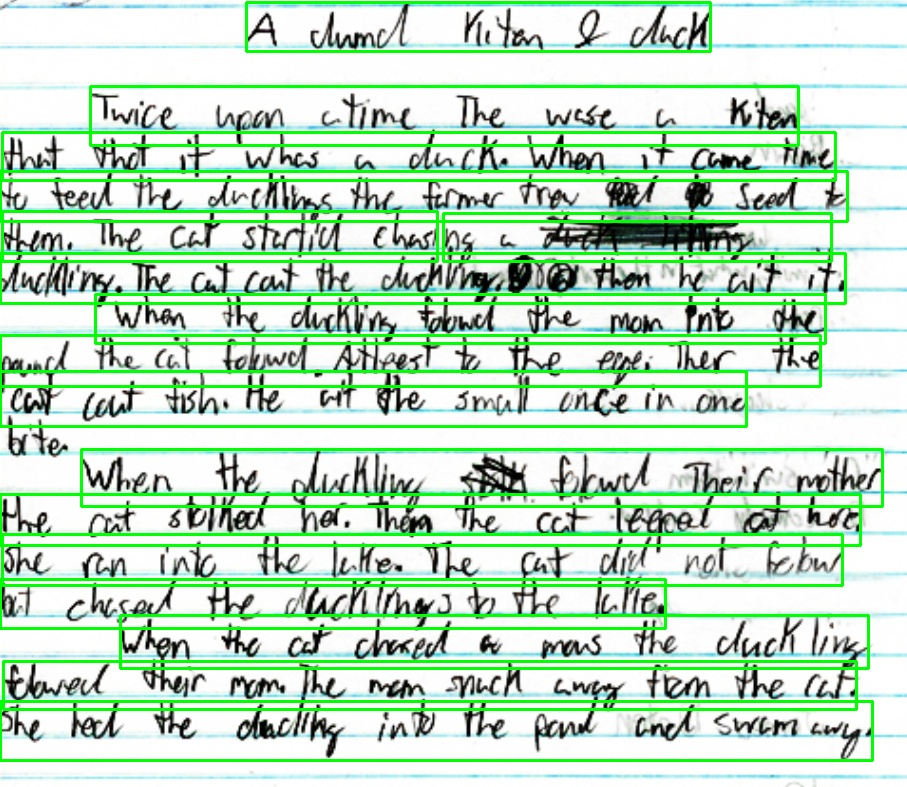

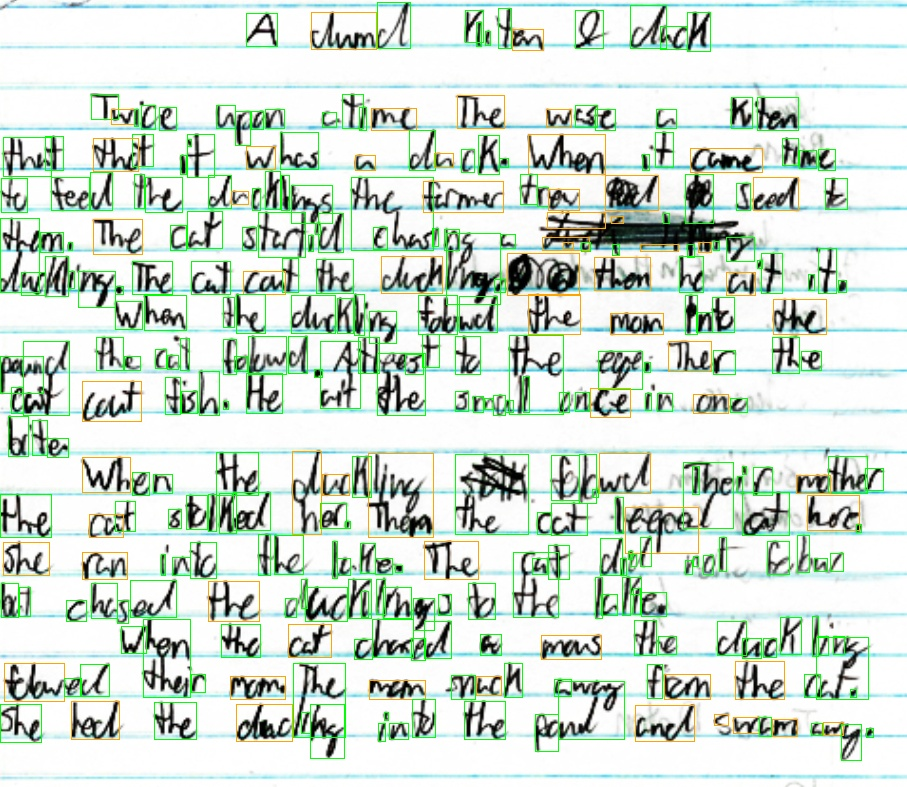

In [6]:
from IPython.display import display
display(Image.open(OUTPUT_DIR / "01_line_preview.jpg"))
display(Image.open(OUTPUT_DIR / "02_character_boxes.jpg"))

## 8. Inspect outputs
- `crops/`: proposed character images.
- `components.csv`: crop filename and original-image coordinates.
- `debug_ink_before.png`, `debug_removed_rules.png`, `debug_ink_after.png`: preprocessing diagnostics.

The pipeline is label-free, but connected/touching letters and scribbles can still create merged or incorrect crops. Check the preview before using the crops with your existing classifier.